# Libs and import data

# PM2.5 Air Quality Analysis and Prediction

## Project Overview

This project analyses air quality data using meteorological
and atmospheric variables to understand and predict PM2.5
concentrations.

## Objectives

- Explore the air quality dataset.
- Analyse missing values and data distributions.
- Examine relationships between atmospheric variables.
- Implement regression algorithms.
- Compare model performance using RMSE.

In [136]:
import warnings
warnings.filterwarnings('ignore')

In [137]:
import pandas as pd

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns

In [139]:
import numpy as np

In [140]:
# if you have not install sklearn (or scikit-learn) and scipy then install it
# ! pip install scikit-learn --user
# ! pip install scipy --user

In [141]:
# let pick up the data has been cleaned up the previous exercise, v3
df = pd.read_csv('comb_PM25_wind_Hanoi_2018_v3.csv',
                 parse_dates=['DATE'],
                 index_col=['DATE'])
df.head()

,PM2.5,T2MDEW,T2M,PS,TQV,TQL,H1000,DISPH,FRCAN,HLML,RHOA,CIG,WS,CLDCR,v_2m,v_50m,v_850
DATE,,,,,,,,,,,,,,,,,
2018-01-01 01:00:00,69.2,10.79443,13.64376,100865.09,34.909637,0.009235,160.25461,0.256226,1.000000,63.907425,1.216159,NaN,NaN,NaN,0.429060,0.979452,6.175777
2018-01-01 02:00:00,75.5,10.72836,13.33932,100819.56,35.195385,0.006260,156.44829,0.256226,1.000000,63.832478,1.217125,NaN,NaN,NaN,0.383400,0.872296,5.997708
2018-01-01 03:00:00,90.2,10.60630,13.09753,100793.71,35.590984,0.003489,154.54437,0.256104,0.993164,63.766266,1.218085,NaN,NaN,NaN,0.339189,0.729687,5.915825
2018-01-01 04:00:00,97.6,10.50967,12.81360,100791.80,35.827934,0.002314,154.16837,0.255981,0.927490,63.718185,1.218972,NaN,NaN,NaN,0.305853,0.666341,5.885087
2018-01-01 05:00:00,89.1,10.49365,12.71010,100808.45,35.953880,0.001480,155.72943,0.255859,0.786133,63.684280,1.219831,NaN,NaN,NaN,0.258492,0.541109,5.796022


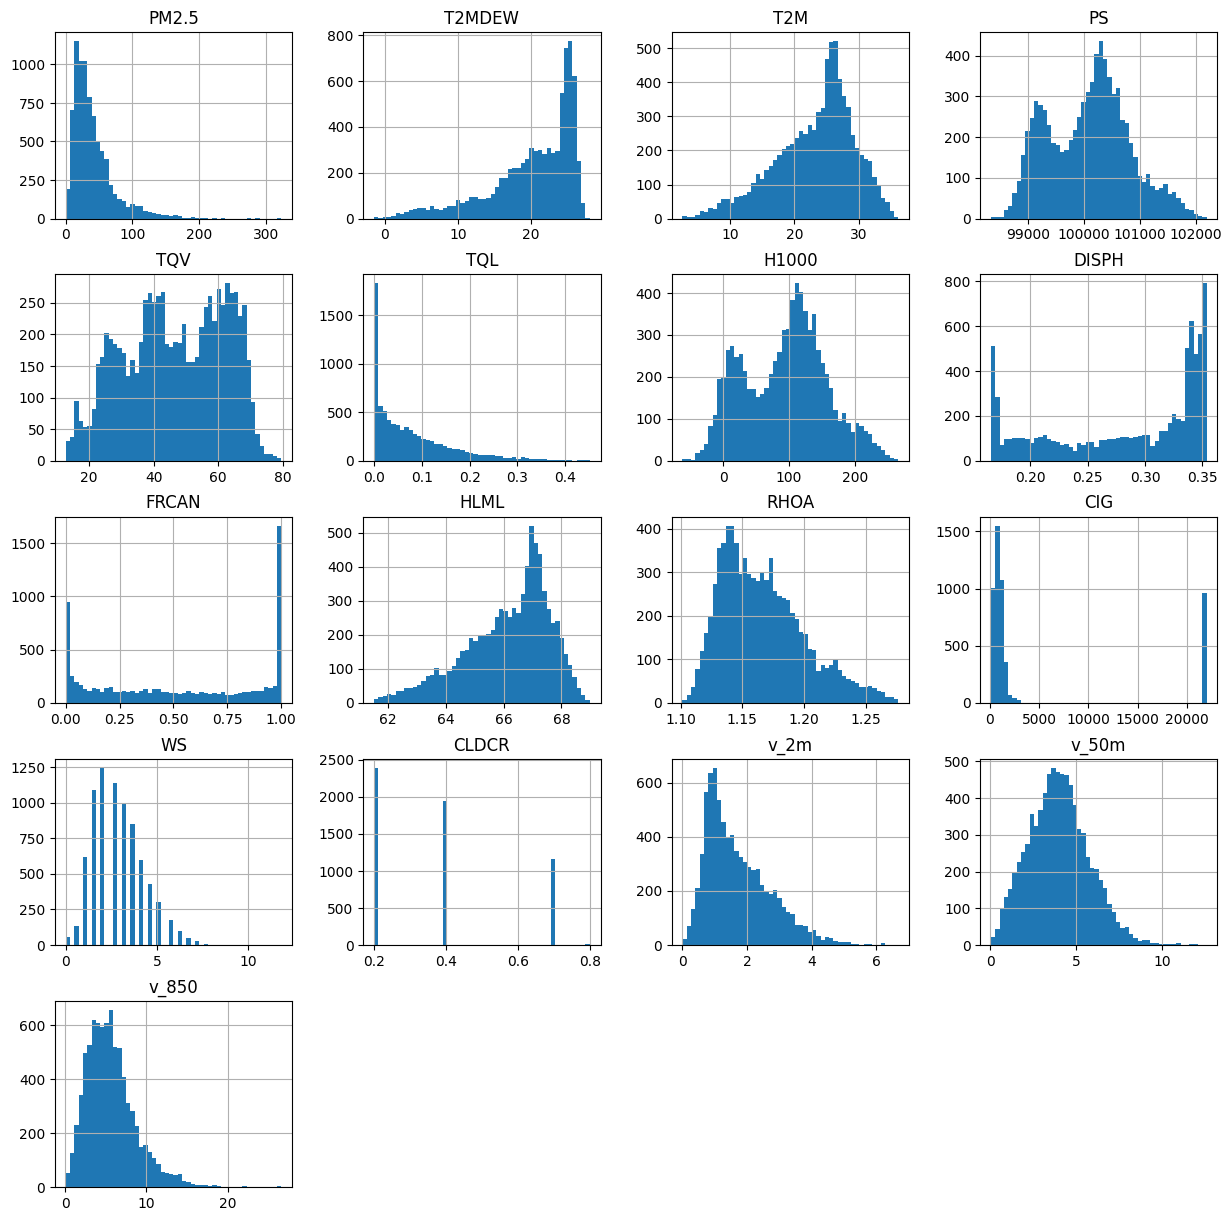

In [142]:
df.hist(bins=50, figsize=(15,15));

# Data Wrangle

## Split data train, test

In [143]:
# the idea is the split the dataset into two parts, one for training, and one for validation
def split_train_test(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data)*test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [144]:
# now we can split them with a ratio like this
train_set, test_set = split_train_test(df, 0.2)

In [145]:
len(train_set)

6493

In [146]:
len(test_set)

1623

In [147]:
# however, the sklearn library has such unility
from sklearn.model_selection import train_test_split

In [148]:
train_set, test_set = train_test_split(df, test_size=0.2, random_state=2020)
print(len(train_set))
train_set.head()

6492


,PM2.5,T2MDEW,T2M,PS,TQV,TQL,H1000,DISPH,FRCAN,HLML,RHOA,CIG,WS,CLDCR,v_2m,v_50m,v_850
DATE,,,,,,,,,,,,,,,,,
2018-11-01 01:00:00,66.0,13.76476,15.91640,100623.33,23.115633,0.000000,140.67795,0.346069,0.000000,65.119470,1.190721,NaN,2.1,NaN,1.317137,5.151577,13.778793
2018-03-11 13:00:00,97.1,16.36712,23.94467,100729.96,37.070614,0.095612,151.08076,0.170471,0.558838,65.698654,1.181534,NaN,2.1,0.4,3.250031,4.604924,5.120155
2018-11-02 17:00:00,28.0,15.21340,22.42794,100487.85,20.839620,0.000000,130.45107,0.345093,0.000000,66.063030,1.172179,NaN,1.0,NaN,0.614779,1.535728,3.374469
2018-03-27 23:00:00,63.7,18.28860,18.51727,100447.27,38.934628,0.004002,126.26744,0.192688,0.044815,65.261230,1.186127,22000.0,3.1,NaN,1.117351,4.444736,6.082646
2018-12-01 04:00:00,55.0,20.01226,20.44995,100557.99,42.091070,0.090057,136.40723,0.316406,0.208740,65.746920,1.178689,792.0,1.5,0.4,0.629109,1.737746,5.265891


## Fill NaN values
- Data are likely assembled with missing values
- Regression or machine learning works better with completed dataset

In [149]:
# make a copy and test out
df1 = df.copy(deep=True)

In [150]:
# calculate the median of the Windspeed (WS) input
median = df1['WS'].median()

In [151]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   DISPH   8116 non-null   float64
 8   FRCAN   8092 non-null   float64
 9   HLML    8092 non-null   float64
 10  RHOA    8092 non-null   float64
 11  CIG     5088 non-null   float64
 12  WS      7809 non-null   float64
 13  CLDCR   5502 non-null   float64
 14  v_2m    8116 non-null   float64
 15  v_50m   8116 non-null   float64
 16  v_850   8116 non-null   float64
dtypes: float64(17)
memory usage: 1.1 MB


In [152]:
df1['WS'].fillna(median, inplace=True)

In [153]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   DISPH   8116 non-null   float64
 8   FRCAN   8092 non-null   float64
 9   HLML    8092 non-null   float64
 10  RHOA    8092 non-null   float64
 11  CIG     5088 non-null   float64
 12  WS      8116 non-null   float64
 13  CLDCR   5502 non-null   float64
 14  v_2m    8116 non-null   float64
 15  v_50m   8116 non-null   float64
 16  v_850   8116 non-null   float64
dtypes: float64(17)
memory usage: 1.1 MB


In [154]:
# we can manually do this by for loop
for col in df1.columns:
    df1[col].fillna(df1[col].median(), inplace=True)
df1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   DISPH   8116 non-null   float64
 8   FRCAN   8116 non-null   float64
 9   HLML    8116 non-null   float64
 10  RHOA    8116 non-null   float64
 11  CIG     8116 non-null   float64
 12  WS      8116 non-null   float64
 13  CLDCR   8116 non-null   float64
 14  v_2m    8116 non-null   float64
 15  v_50m   8116 non-null   float64
 16  v_850   8116 non-null   float64
dtypes: float64(17)
memory usage: 1.1 MB


In [155]:
# and sklearn has the Class to do such
from sklearn.impute import SimpleImputer

In [156]:
inputer = SimpleImputer(strategy='median')

In [157]:
df2 =df.copy(deep=True)
df2.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   DISPH   8116 non-null   float64
 8   FRCAN   8092 non-null   float64
 9   HLML    8092 non-null   float64
 10  RHOA    8092 non-null   float64
 11  CIG     5088 non-null   float64
 12  WS      7809 non-null   float64
 13  CLDCR   5502 non-null   float64
 14  v_2m    8116 non-null   float64
 15  v_50m   8116 non-null   float64
 16  v_850   8116 non-null   float64
dtypes: float64(17)
memory usage: 1.1 MB


In [158]:
# evaluate df2
inputer.fit(df2)

SimpleImputer(strategy='median')

In [159]:
# see the statistic, median in this case
inputer.statistics_

array([3.20000000e+01, 2.17670550e+01, 2.45143500e+01, 1.00156612e+05,
       4.69396705e+01, 5.37109380e-02, 1.01305442e+02, 3.08166505e-01,
       5.11840850e-01, 6.64740250e+01, 1.16165940e+00, 9.45000000e+02,
       2.60000000e+00, 4.00000000e-01, 1.48621393e+00, 3.92495231e+00,
       5.23608490e+00])

In [160]:
# transform is doing the work
df2full = inputer.transform(df1)

In [161]:
type(df2full)

numpy.ndarray

In [162]:
# convert the inputed dataset and  compared
df2 = pd.DataFrame(data=df2full, columns=df1.columns)
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8116 entries, 0 to 8115
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   DISPH   8116 non-null   float64
 8   FRCAN   8116 non-null   float64
 9   HLML    8116 non-null   float64
 10  RHOA    8116 non-null   float64
 11  CIG     8116 non-null   float64
 12  WS      8116 non-null   float64
 13  CLDCR   8116 non-null   float64
 14  v_2m    8116 non-null   float64
 15  v_50m   8116 non-null   float64
 16  v_850   8116 non-null   float64
dtypes: float64(17)
memory usage: 1.1 MB


(0.0, 200.0)

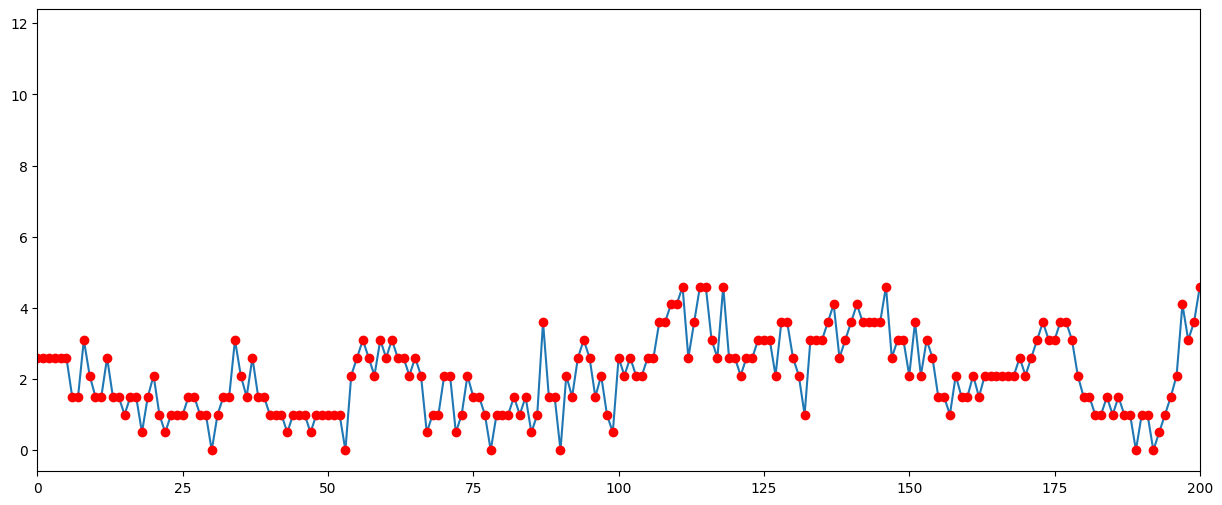

In [163]:
# let see if they are matched
fig, ax = plt.subplots(figsize=(15,6))
ax.plot(df1.WS.to_list())
ax.plot(df2.WS, 'ro')
ax.set_xlim(0,200)

## Additional cleanup

<Axes: >

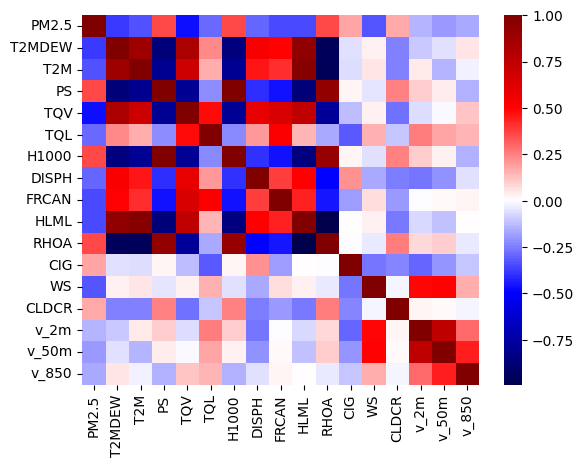

In [164]:
# let return back to the original dataset (df) before fill up NaN
sns.heatmap(df.corr(), cmap='seismic')

<Axes: >

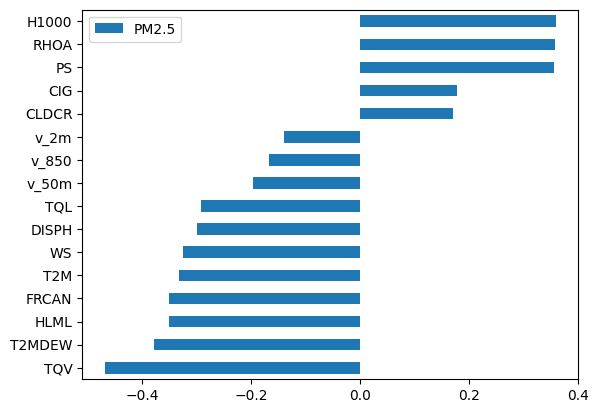

In [165]:
# and only correlation with PM2.5
df.corr()['PM2.5'].sort_values().to_frame().drop('PM2.5').plot.barh()

In [166]:
df.columns

Index(['PM2.5', 'T2MDEW', 'T2M', 'PS', 'TQV', 'TQL', 'H1000', 'DISPH', 'FRCAN',
       'HLML', 'RHOA', 'CIG', 'WS', 'CLDCR', 'v_2m', 'v_50m', 'v_850'],
      dtype='object')

In [167]:
# drop some columns either weak in correation or dependent (redundant) to other inputs
df.drop(columns=['CLDCR', 'v_2m', 'v_50m', 'v_850', 'FRCAN', 'DISPH'], inplace=True)

In [168]:
df.head()

,PM2.5,T2MDEW,T2M,PS,TQV,TQL,H1000,HLML,RHOA,CIG,WS
DATE,,,,,,,,,,,
2018-01-01 01:00:00,69.2,10.79443,13.64376,100865.09,34.909637,0.009235,160.25461,63.907425,1.216159,NaN,NaN
2018-01-01 02:00:00,75.5,10.72836,13.33932,100819.56,35.195385,0.006260,156.44829,63.832478,1.217125,NaN,NaN
2018-01-01 03:00:00,90.2,10.60630,13.09753,100793.71,35.590984,0.003489,154.54437,63.766266,1.218085,NaN,NaN
2018-01-01 04:00:00,97.6,10.50967,12.81360,100791.80,35.827934,0.002314,154.16837,63.718185,1.218972,NaN,NaN
2018-01-01 05:00:00,89.1,10.49365,12.71010,100808.45,35.953880,0.001480,155.72943,63.684280,1.219831,NaN,NaN


In [169]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   HLML    8092 non-null   float64
 8   RHOA    8092 non-null   float64
 9   CIG     5088 non-null   float64
 10  WS      7809 non-null   float64
dtypes: float64(11)
memory usage: 760.9 KB


## Split features (meteorological inputs) and label (PM<sub>2.5</sub>)

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8116 entries, 2018-01-01 01:00:00 to 2018-12-31 00:00:00
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PM2.5   8116 non-null   float64
 1   T2MDEW  8116 non-null   float64
 2   T2M     8116 non-null   float64
 3   PS      8116 non-null   float64
 4   TQV     8116 non-null   float64
 5   TQL     8116 non-null   float64
 6   H1000   8116 non-null   float64
 7   HLML    8092 non-null   float64
 8   RHOA    8092 non-null   float64
 9   CIG     5088 non-null   float64
 10  WS      7809 non-null   float64
dtypes: float64(11)
memory usage: 760.9 KB


In [171]:
# let make X as the matrix for the feature (or inputs)
X = df.drop('PM2.5', axis=1)

In [172]:
# and lowercase y as the label (or the value of the target)
y = df['PM2.5'].copy()

In [173]:
# let build the inpute instance to work with whole data at one
# to inpute more than one columns, we can use this
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [174]:
# transform data from real value to a relative to the set
from sklearn.preprocessing import StandardScaler

In [175]:
# we have all column with numeric values
num_attrs = list(df.columns)
num_attrs.remove('PM2.5')
num_attrs

['T2MDEW', 'T2M', 'PS', 'TQV', 'TQL', 'H1000', 'HLML', 'RHOA', 'CIG', 'WS']

In [176]:
# first is the trategy for inputer using median
# then convert the absolute value in the each column using the Standard Class
num_pipeline = Pipeline([
        ('inputer', SimpleImputer(strategy='median')),
        ('std_scaler', StandardScaler()),
        ])

In [177]:
# and instance to tranform all column at one
full_pipeline = ColumnTransformer([
    ('num', num_pipeline, num_attrs)
])

In [178]:
# or building a function to do all in one step
def inpute_transfrom(data=None):
    num_pipeline = Pipeline([
        ('inputer', SimpleImputer(strategy='median')),
        ('std_scaler', StandardScaler()),
        ])
    num_attrs = list(data.columns)
    full_pipeline = ColumnTransformer([
        ('num', num_pipeline, num_attrs)
        ])
    return full_pipeline.fit_transform(data) # return a numpy array

In [179]:
X_scaled = inpute_transfrom(data=X)

In [180]:
# how do we know that the data has been fixed properly
X_scaled_test = inpute_transfrom(data=X)
dft = pd.DataFrame(data=X_scaled_test, columns=num_attrs)
dft.info()
# looking good
del dft

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8116 entries, 0 to 8115
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   T2MDEW  8116 non-null   float64
 1   T2M     8116 non-null   float64
 2   PS      8116 non-null   float64
 3   TQV     8116 non-null   float64
 4   TQL     8116 non-null   float64
 5   H1000   8116 non-null   float64
 6   HLML    8116 non-null   float64
 7   RHOA    8116 non-null   float64
 8   CIG     8116 non-null   float64
 9   WS      8116 non-null   float64
dtypes: float64(10)
memory usage: 634.2 KB


In [181]:
# now we can split data, the test_size is the portion of data use for validation
# random_state is to provide consistent if you want to replicate the result
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y, test_size=0.33, random_state=2020)

In [182]:
len(X_train), len(X_test)

(5437, 2679)

# Linear Regression

In [183]:
# Linear regression is the simplest form of data learning, let try this first
from sklearn.linear_model import LinearRegression

In [184]:
# make an instant of the class
lin_reg = LinearRegression()

In [185]:
# and training the model using the _train dataset
lin_reg.fit(X_train, y_train)

LinearRegression()

In [186]:
lin_reg.get_params()

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

In [187]:
# let see the output of the mode
lin_reg.coef_

array([  -3.15806877,    9.23068653, -237.20129647,  -11.37237178,
         -1.51486159,  216.26310513,   19.10913327,   47.2122002 ,
          2.99459991,   -8.55437448])

In [188]:
# predict based on the training set
y_train_prd = lin_reg.predict(X_train)

(0.0, 500.0)

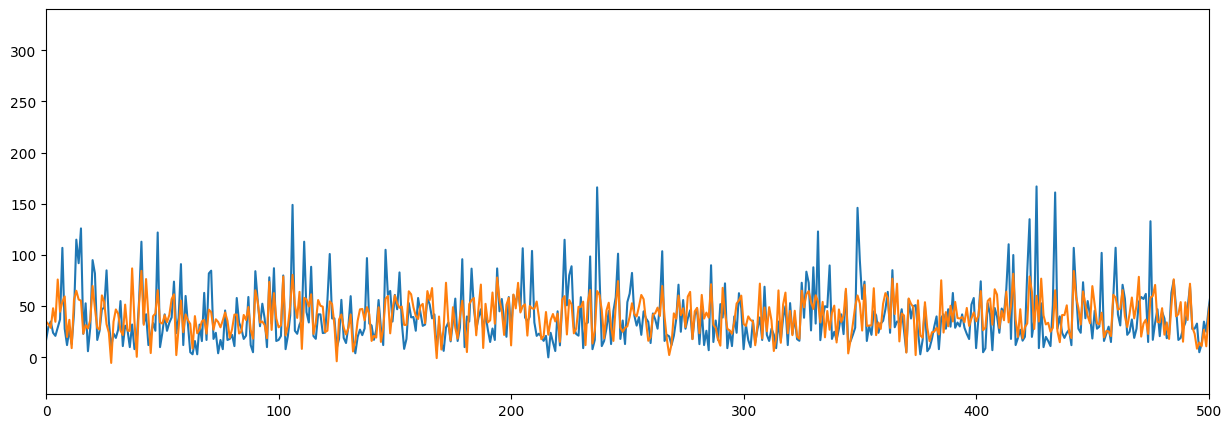

In [189]:
# let see how the label (y_train), and predicting of the label (y_prd)
plt.figure(figsize=(15,5))
plt.plot(y_train.to_list())
plt.plot(y_train_prd)
plt.xlim(0,500)

In [190]:
# more important, how about with validation set (test set)
y_test_prd = lin_reg.predict(X_test)

(0.0, 500.0)

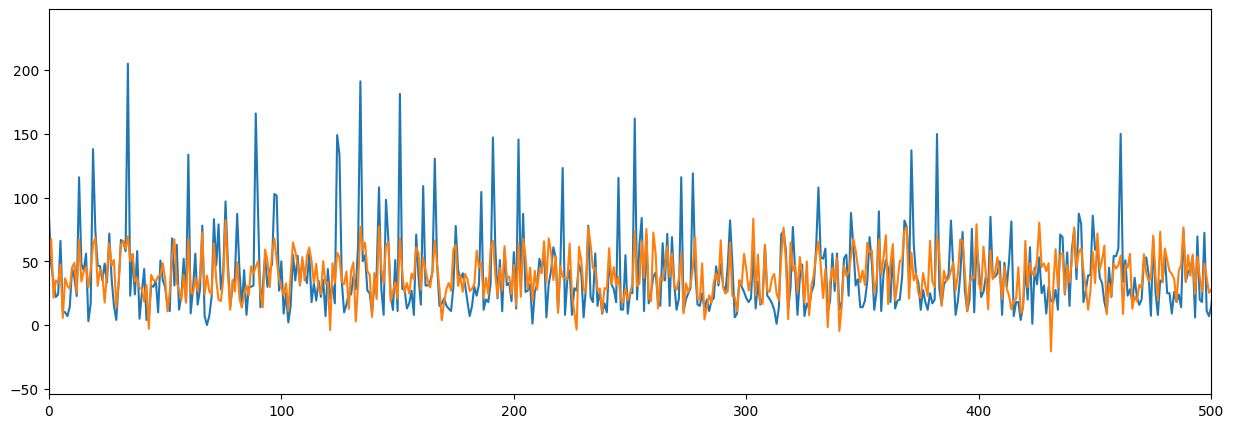

In [191]:
plt.figure(figsize=(15,5))
plt.plot(y_test.to_list())
plt.plot(y_test_prd)
plt.xlim(0,500)

- kind of there, but not easy to assess

## evaluate model performance

In [192]:
# for numeric data, one simple way to to see how far
# between the prediction and the garget
from sklearn.metrics import mean_squared_error

In [193]:
# on training set
lin_train_mse = mean_squared_error(y_train, y_train_prd)
print('Trainset: Root Squared Mean Error', np.sqrt(lin_train_mse))

Trainset: Root Squared Mean Error 25.50502509220003


In [194]:
# on test set
lin_test_mse = mean_squared_error(y_test, y_test_prd)
print('Test set: Root Squared Mean Error', np.sqrt(lin_test_mse))

Test set: Root Squared Mean Error 25.924922211091516


In [195]:
# the average value label set (y set)
y.mean()

np.float64(40.758735830458356)

In [196]:
# relative error
print(f'Relative Error: {100*np.sqrt(lin_test_mse)/y.mean():.0f}%')

Relative Error: 64%


- underfitting (data), we have can predict the PM<sub>2.5</sub> concentration, but bear in mind the value can be off 64% (up and down), and that only works 66 out of 100 chances (given the error is random)
- let try another model, also, make a dictionary to keep the score between model

In [197]:
results = dict()
def add_stats(model=None, train_rmse=None, test_rmse=None):
    global results
    results[model] = {'train_rmse': round(train_rmse,1),
                     'test_rmse': round(test_rmse, 1)}
    return None

In [198]:
add_stats(model='linear reg',
         train_rmse=np.sqrt(lin_train_mse),
         test_rmse=np.sqrt(lin_test_mse))
results

{'linear reg': {'train_rmse': np.float64(25.5), 'test_rmse': np.float64(25.9)}}

# DecisionTree

In [199]:
# let try the same approach with decision tree
from sklearn.tree import DecisionTreeRegressor

In [200]:
tree_reg = DecisionTreeRegressor()

In [201]:
tree_reg.fit(X_train, y_train)

DecisionTreeRegressor()

In [202]:
tree_reg.feature_importances_

array([0.28939915, 0.06361704, 0.06490308, 0.13920736, 0.10215384,
       0.05173503, 0.05487861, 0.04848015, 0.07153848, 0.11408727])

In [203]:
tree_ytrain_d = tree_reg.predict(X_train)

In [204]:
# no error, too good!
tree_train_rmse = np.sqrt(mean_squared_error(y_train, tree_ytrain_d))
tree_train_rmse

np.float64(0.0)

In [205]:
tree_ytest_d = tree_reg.predict(X_test)

In [206]:
tree_test_rmse = np.sqrt(mean_squared_error(y_test, tree_ytest_d))
tree_test_rmse # higher than regression,

np.float64(28.76931910104734)

In [207]:
# let bag the result
add_stats(model='decisiontree reg',
         train_rmse=tree_train_rmse,
         test_rmse=tree_test_rmse)
results

{'linear reg': {'train_rmse': np.float64(25.5), 'test_rmse': np.float64(25.9)},
 'decisiontree reg': {'train_rmse': np.float64(0.0),
  'test_rmse': np.float64(28.8)}}

In [208]:
# the results by train set and test set are rather different, to see it
def plot_prediction(label=None, prediction=None, limit=200):
    plt.figure(figsize=(14,6))
    plt.plot(label.to_list())
    plt.plot(prediction, 'ro')
    plt.xlim(0, limit)
    return None

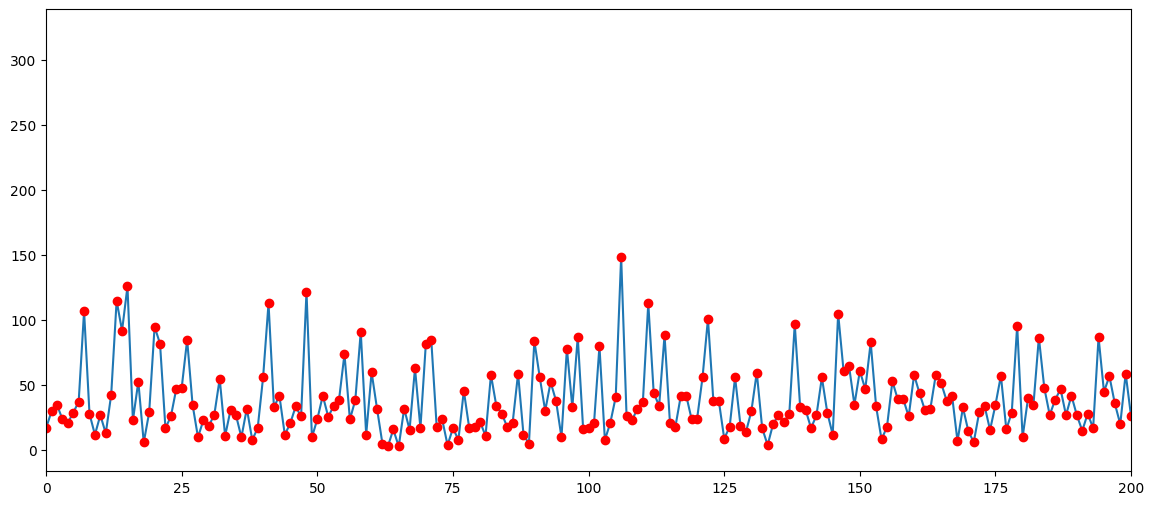

In [209]:
plot_prediction(y_train, tree_ytrain_d)

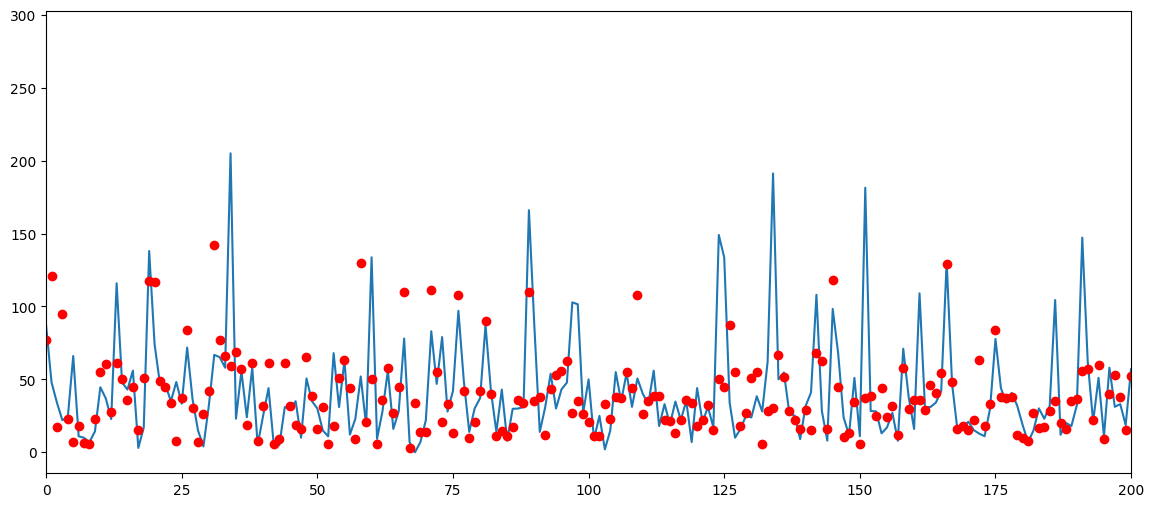

In [210]:
plot_prediction(y_test, tree_ytest_d)

- overfitting data for training set (memorization), and underfitting with test set (not map key feature)

## RandomForest

In [211]:
# more powerful model
from sklearn.ensemble import RandomForestRegressor

In [212]:
forest_reg = RandomForestRegressor()
forest_reg.fit(X_train, y_train)

RandomForestRegressor()

In [213]:
forest_ytrain_p = forest_reg.predict(X_train)

In [214]:
mse_train = mean_squared_error(y_train, forest_ytrain_p)
rmse_train = np.sqrt(mse_train)
rmse_train

np.float64(7.22801878592022)

In [215]:
# test set
forest_ytest_p = forest_reg.predict(X_test)

In [216]:
mse_test = mean_squared_error(y_test, forest_ytest_p)
rmse_test = np.sqrt(mse_test)
rmse_test

np.float64(20.11829409953912)

In [217]:
add_stats(model='randomforest reg',
         train_rmse=rmse_train,
         test_rmse=rmse_test)
results

{'linear reg': {'train_rmse': np.float64(25.5), 'test_rmse': np.float64(25.9)},
 'decisiontree reg': {'train_rmse': np.float64(0.0),
  'test_rmse': np.float64(28.8)},
 'randomforest reg': {'train_rmse': np.float64(7.2),
  'test_rmse': np.float64(20.1)}}

## Cross validation

In [218]:
from sklearn.model_selection import cross_val_score

In [219]:
scores = cross_val_score(tree_reg, X_train, y_train,
                        scoring='neg_mean_squared_error', cv=10)

In [220]:
tree_rmse_scores = np.sqrt(-scores)
tree_rmse_scores

array([25.31602426, 28.10986325, 27.3332703 , 28.74354403, 27.08090954,
       28.3754619 , 25.10469292, 31.97739245, 27.75470693, 27.38286051])

In [221]:
def display_scores(scores):
    print("Scores: ", scores)
    print("Mean: ", scores.mean())
    print("Standard Deviation: ", scores.std())

In [222]:
display_scores(scores)

Scores:  [ -640.90108456  -790.16441176  -747.10766544  -826.19132353
  -733.37566176  -805.16683824  -630.24560662 -1022.55362799
  -770.32375691  -749.82104972]
Mean:  -771.5851026534232
Standard Deviation:  103.45506308758539


In [223]:
lin_scores = cross_val_score(lin_reg, X_train, y_train,
                             scoring='neg_mean_squared_error', cv=10)

In [224]:
display_scores(lin_scores)

Scores:  [-550.85870613 -723.57425609 -604.74504505 -774.75436464 -558.6424609
 -650.90144343 -694.9417229  -791.12250196 -464.54518714 -719.45029524]
Mean:  -653.3535983471007
Standard Deviation:  101.11405749157913


In [225]:
forest_scores = cross_val_score(forest_reg, X_train, y_train,
                                scoring='neg_mean_squared_error', cv=10)

In [226]:
display_scores(forest_scores)

Scores:  [-331.24624673 -390.99528651 -345.3891343  -490.58564772 -333.98501112
 -336.08409918 -426.22342337 -543.71515285 -259.11430855 -398.99826964]
Mean:  -385.6336579974342
Standard Deviation:  79.72895810131607


In [227]:
# how about on test set:
for model in [lin_reg, tree_reg, forest_reg]:
    scores = cross_val_score(model, X_test, y_test,
                             scoring='neg_mean_squared_error', cv=10)
    display_scores(scores)
    print('-'*40)


Scores:  [-771.63467574 -554.4382247  -813.16490696 -717.49508355 -598.56766015
 -632.13746509 -569.73439949 -753.33939901 -661.54505262 -680.24197289]
Mean:  -675.2298840188973
Standard Deviation:  83.59053107056987
----------------------------------------
Scores:  [-1310.91298507  -755.57037313  -908.7766791   -960.78141791
  -749.43992537  -911.12914179  -726.03783582  -874.73287313
  -835.83563433  -855.49794007]
Mean:  -888.8714805746547
Standard Deviation:  158.75557474526653
----------------------------------------
Scores:  [-612.29460464 -369.91800796 -565.33873919 -523.27993374 -316.51834836
 -444.97590287 -308.15780925 -498.75261001 -563.25722552 -435.01664786]
Mean:  -463.7509829398723
Standard Deviation:  101.45198824114061
----------------------------------------


- look like the RandomForest Regression performs a bit better than the first two

## save model

In [228]:
# just in case you want to save your work
import joblib

In [229]:
# import os
# os.makedirs('model')

In [230]:
import os
os.makedirs('model', exist_ok=True)
joblib.dump(forest_reg, 'model/forest_reg.pkl')

['model/forest_reg.pkl']

## Grid Search

In [231]:
# we want to model performs better, in this case we tune the hyperparameters
from sklearn.model_selection import GridSearchCV

In [232]:
param_grid = [{'n_estimators': [3, 10, 30], 'max_features': [2, 4, 6, 8]},
              {'bootstrap': [False], 'n_estimators': [3, 10], 'max_features': [2, 3, 4]},]

In [233]:
forest_reg = RandomForestRegressor()
grid_search = GridSearchCV(forest_reg, param_grid, cv=5,
                           scoring='neg_mean_squared_error',
                          return_train_score=True)

In [131]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(),
             param_grid=[{'max_features': [2, 4, 6, 8],
                          'n_estimators': [3, 10, 30]},
                         {'bootstrap': [False], 'max_features': [2, 3, 4],
                          'n_estimators': [3, 10]}],
             return_train_score=True, scoring='neg_mean_squared_error')

In [132]:
# and see the best estimator
grid_search.best_estimator_

RandomForestRegressor(max_features=4, n_estimators=30)

In [133]:
# or best parameters
grid_search.best_params_

{'max_features': 4, 'n_estimators': 30}

In [134]:
# or see the how each combination has worked
cvres = grid_search.cv_results_

In [135]:
for mean_score, params in zip(cvres['mean_test_score'], cvres['params']):
    print(round(np.sqrt(-mean_score),2), params)

24.31 {'max_features': 2, 'n_estimators': 3}
21.38 {'max_features': 2, 'n_estimators': 10}
20.4 {'max_features': 2, 'n_estimators': 30}
23.59 {'max_features': 4, 'n_estimators': 3}
20.76 {'max_features': 4, 'n_estimators': 10}
20.07 {'max_features': 4, 'n_estimators': 30}
23.77 {'max_features': 6, 'n_estimators': 3}
20.61 {'max_features': 6, 'n_estimators': 10}
20.11 {'max_features': 6, 'n_estimators': 30}
23.61 {'max_features': 8, 'n_estimators': 3}
20.95 {'max_features': 8, 'n_estimators': 10}
20.14 {'max_features': 8, 'n_estimators': 30}
22.54 {'bootstrap': False, 'max_features': 2, 'n_estimators': 3}
20.46 {'bootstrap': False, 'max_features': 2, 'n_estimators': 10}
22.92 {'bootstrap': False, 'max_features': 3, 'n_estimators': 3}
20.4 {'bootstrap': False, 'max_features': 3, 'n_estimators': 10}
22.84 {'bootstrap': False, 'max_features': 4, 'n_estimators': 3}
20.15 {'bootstrap': False, 'max_features': 4, 'n_estimators': 10}


- so the best case with Random Forecast is 19.98 (&mu;g/m<sup>3</sup>) as the standard deviation

## Analyze model

In [235]:
# Fit the grid search if it hasn't been fitted yet to populate best_estimator_
try:
    feature_importances = grid_search.best_estimator_.feature_importances_
except AttributeError:
    print("GridSearchCV was not fitted. Fitting now...")
    grid_search.fit(X_train, y_train)
    feature_importances = grid_search.best_estimator_.feature_importances_

feature_importances

GridSearchCV was not fitted. Fitting now...


array([0.20020743, 0.07169432, 0.07639169, 0.1661811 , 0.09931523,
       0.07501754, 0.0582129 , 0.06212648, 0.07788367, 0.11296963])

In [ ]:
sorted(zip(feature_importances, X.columns), reverse=True)

- so the total liquid volumn and dewpoint influences PM<sub>2.5</sub> more than the air temperature or surface level height

In [ ]:
# let see how grid search performs
# train set
grid_ytrain_p = grid_search.predict(X_train)
grid_mse = mean_squared_error(y_train, grid_ytrain_p)
grid_train_rmse = np.sqrt(grid_mse)
grid_train_rmse

In [ ]:
# let see how the prediction look like after hypertunning
# test set
grid_ytest_p = grid_search.predict(X_test)
grid_test_mse = mean_squared_error(y_test, grid_ytest_p)
grid_test_rmse = np.sqrt(grid_test_mse)
grid_test_rmse

In [ ]:
# still more to work with, but let bag the result for later comparison
add_stats(model='gridsearch',
         train_rmse=grid_train_rmse,
         test_rmse=grid_test_rmse)
results

In [ ]:
# let visualize it
std_ = grid_test_rmse
xindex = np.arange(0, len(y_test))
fig, ax = plt.subplots(figsize=(15,6))
ax.plot(y_test.to_list(), color='black', label='measured')
ax.plot(grid_ytest_p, color='red', alpha=0.8, label='predicted')
ax.fill_between(xindex, grid_ytest_p-std_,grid_ytest_p+std_,
                color='red', alpha=0.3, label='1signma' )
ax.fill_between(xindex, grid_ytest_p-2*std_,grid_ytest_p+2*std_,
                color='red', alpha=0.2, label = '2sigma')
ax.set_xlim(0,200)
ax.legend()

- an easy way to make sure the prediction range captures the real value is to increase the band, and so enlarge the uncertainty
- but let see how confidence we have on the RSME,

## Scipy interval 95%

In [ ]:
# let use stats from scipy library
from scipy import stats

In [ ]:
# and look confidence of .95, or the area that a value will be inside the range with 95 chances of 100
confidence = 0.95

In [ ]:
squared_errors = (grid_ytest_p - y_test)**2

In [ ]:
np.sqrt(stats.t.interval(
    confidence,
    len(squared_errors)-1,
    loc=squared_errors.mean(),
    scale=stats.sem(squared_errors)))

- so we are pretty sure that standard deviation from grid search is from 18.8 to 21.1
- how confidience: 95 chances out of 100, this RMSE will be within this range

## Ensemble Methods

In [ ]:
# let look at a final approach to combine three regression we have so far using Voting method
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
# re-define an instance, all training in the previous sessions are gone
lin_reg  = LinearRegression()
tree_reg = DecisionTreeRegressor()
rnd_reg = RandomForestRegressor()

In [ ]:
# and make each model as an parameter for then ensemble (voting)
voting_reg = VotingRegressor(
    estimators=[('lin', lin_reg),
               ('rnd', rnd_reg),
               ('tree', tree_reg)
               ],
)

In [ ]:
# train model by the train set
voting_reg.fit(X_train, y_train)

In [ ]:
# check estimator (paramters)
voting_reg.estimators_

In [ ]:
# now we do predicting on the test set
y_entest_p = voting_reg.predict(X_test)

In [238]:
from sklearn.ensemble import VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Ensure model is defined and fitted if namespace was cleared
try:
    voting_reg
except NameError:
    lin_reg = LinearRegression()
    tree_reg = DecisionTreeRegressor()
    rnd_reg = RandomForestRegressor()
    voting_reg = VotingRegressor(
        estimators=[('lin', lin_reg), ('rnd', rnd_reg), ('tree', tree_reg)]
    )
    voting_reg.fit(X_train, y_train)

# Ensure predictions are computed
try:
    y_entest_p
except NameError:
    y_entest_p = voting_reg.predict(X_test)

mse = mean_squared_error(y_entest_p, y_test)
en_test = np.sqrt(mse)
en_test

np.float64(21.775732455547335)

In [239]:
# we could run on train set
y_entrain_p = voting_reg.predict(X_train)
mse = mean_squared_error(y_entrain_p, y_train)
en_train = np.sqrt(mse)

In [240]:
en_test, en_train

(np.float64(21.775732455547335), np.float64(10.543203710752046))

In [241]:
# still in 21 for test set
add_stats(model='voting reg',
         train_rmse=en_train,
         test_rmse=en_test)
results

{'linear reg': {'train_rmse': np.float64(25.5), 'test_rmse': np.float64(25.9)},
 'decisiontree reg': {'train_rmse': np.float64(0.0),
  'test_rmse': np.float64(28.8)},
 'randomforest reg': {'train_rmse': np.float64(7.2),
  'test_rmse': np.float64(20.1)},
 'voting reg': {'train_rmse': np.float64(10.5), 'test_rmse': np.float64(21.8)}}

(200.0, 300.0)

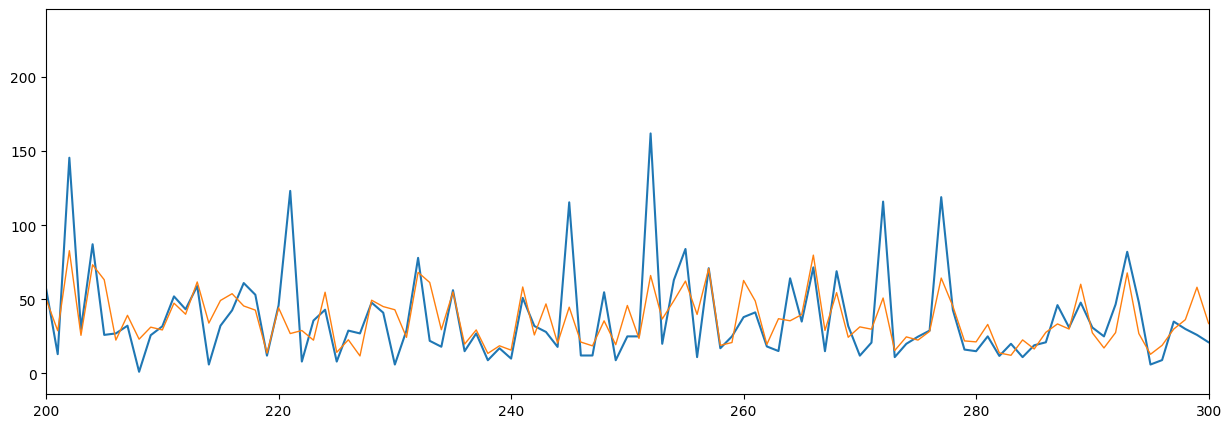

In [242]:
# let visualize the data from Ensemble with test set
plt.figure(figsize=(15,5))
plt.plot(y_test.to_list())
plt.plot(y_entest_p, lw=1)
plt.xlim(200,300)

- so we can get a RMSE = 20 from several model, which is about 50% as the relative standard deviation
- this dataset is combined from several source, but not easy to get from a forecast product (in fact, I am struggling to get those), so we will try out a dataset with less feastures,

## Split train and test

In [243]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y, test_size=0.33, random_state=2020)

In [244]:
len(X_train), len(y_train)

(5437, 5437)

In [245]:
len(X_test), len(X_test)

(2679, 2679)

## Train and validate

In [246]:
# I will jump in and use voting (seem safer)
lin_reg  = LinearRegression()
tree_reg = DecisionTreeRegressor()
rnd_reg = RandomForestRegressor()
voting_reg = VotingRegressor(
    estimators=[('lin', lin_reg),
               ('rnd', rnd_reg),
               ('tree', tree_reg)
               ],
)

In [247]:
voting_reg.fit(X_train, y_train)

VotingRegressor(estimators=[('lin', LinearRegression()),
                            ('rnd', RandomForestRegressor()),
                            ('tree', DecisionTreeRegressor())])

In [248]:
voting_reg.estimators_

[LinearRegression(), RandomForestRegressor(), DecisionTreeRegressor()]

### Trainset

In [249]:
y_entrain_p = voting_reg.predict(X_train)

In [250]:
mse = mean_squared_error(y_entrain_p, y_train)
train_std = np.sqrt(mse)
train_std

np.float64(10.54804415536801)

In [251]:
y_train.iloc[0:100]

,PM2.5
DATE,
2018-04-30 07:00:00,17.1
2018-05-14 00:00:00,29.9
2018-03-16 18:00:00,35.0
2018-04-06 01:00:00,24.0
2018-08-05 01:00:00,21.0
...,...
2018-09-03 10:00:00,10.0
2018-02-10 00:00:00,78.2
2018-07-24 00:00:00,33.0


In [252]:
from random import randint

In [253]:
# time to invest some good graphs
def plot_results(label=None, prediction=None, std_=None, points=100, savefig=False):
    plt.style.use('default')
    plt.rcParams['font.size'] = 12
    start = randint(0, len(label)-points)
    end = start + points
    label_ = label.iloc[start:end]
    pred_ = prediction[start:end]
    xindex = np.arange(0,len(label_),1)

    plt.figure(figsize=(10,6))
    plt.plot(label_.to_list(), 'ko--',lw=0.5, label='measured')
    plt.plot(pred_, lw=1, color='#922B21', label='predicted')
    plt.fill_between(xindex, pred_- std_, pred_+std_,
                    color='#5499C7', alpha=0.6, label = '$\pm1 \sigma$')

    max_ = np.max([label_.max(), np.max(pred_)])
    plt.ylim(0, 1.1*max_)
    plt.ylabel('Concentration, $\mu g/m^3$')
    plt.title('Measured and predicted $PM_{2.5}$ using Ensemble regression',
              y=1.05, weight='bold')
    plt.xlabel('Hour, site: Hanoi, 2018')
    plt.legend(ncol=3)
    if savefig:
        plt.tight_layout()
        plt.savefig(f'img/en_reg_{start}.png', optimize=True)
    return None

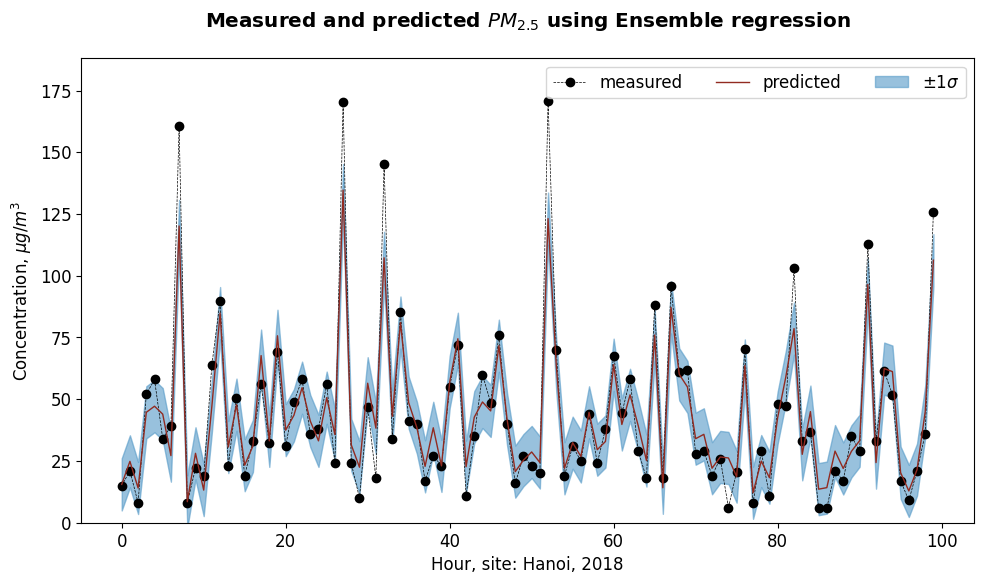

In [255]:
# Redefining plot_results to fix the TypeError when saving as PNG
def plot_results_fixed(label=None, prediction=None, std_=None, points=100, savefig=False):
    plt.style.use('default')
    plt.rcParams['font.size'] = 12
    start = randint(0, len(label)-points)
    end = start + points
    label_ = label.iloc[start:end]
    pred_ = prediction[start:end]
    xindex = np.arange(0,len(label_),1)

    plt.figure(figsize=(10,6))
    plt.plot(label_.to_list(), 'ko--',lw=0.5, label='measured')
    plt.plot(pred_, lw=1, color='#922B21', label='predicted')
    plt.fill_between(xindex, pred_- std_, pred_+std_,
                    color='#5499C7', alpha=0.6, label = '$\pm1 \sigma$')

    max_ = np.max([label_.max(), np.max(pred_)])
    plt.ylim(0, 1.1*max_)
    plt.ylabel('Concentration, $\mu g/m^3$')
    plt.title('Measured and predicted $PM_{2.5}$ using Ensemble regression',
              y=1.05, weight='bold')
    plt.xlabel('Hour, site: Hanoi, 2018')
    plt.legend(ncol=3)
    if savefig:
        plt.tight_layout()
        import os
        os.makedirs('img', exist_ok=True)
        plt.savefig(f'img/en_reg_{start}.png')  # Removed unsupported optimize=True
    return None

plot_results_fixed(label=y_train, prediction=y_entrain_p,
                   std_=train_std, savefig=True)

### Testset

In [256]:
y_entest_p = voting_reg.predict(X_test)

In [257]:
mse = mean_squared_error(y_entest_p, y_test)
test_std = np.sqrt(mse)
mse, test_std

(473.6588249097834, np.float64(21.763704301193382))

In [259]:
add_stats(model='voting reg (Darksky)',
         train_rmse=train_std,
         test_rmse=test_std)
results

{'linear reg': {'train_rmse': np.float64(25.5), 'test_rmse': np.float64(25.9)},
 'decisiontree reg': {'train_rmse': np.float64(0.0),
  'test_rmse': np.float64(28.8)},
 'randomforest reg': {'train_rmse': np.float64(7.2),
  'test_rmse': np.float64(20.1)},
 'voting reg': {'train_rmse': np.float64(10.5), 'test_rmse': np.float64(21.8)},
 'voting reg (Darksky)': {'train_rmse': np.float64(10.5),
  'test_rmse': np.float64(21.8)}}

- not much worse, in fact, with less parameters and get a similar outcome, that is actually encouraging

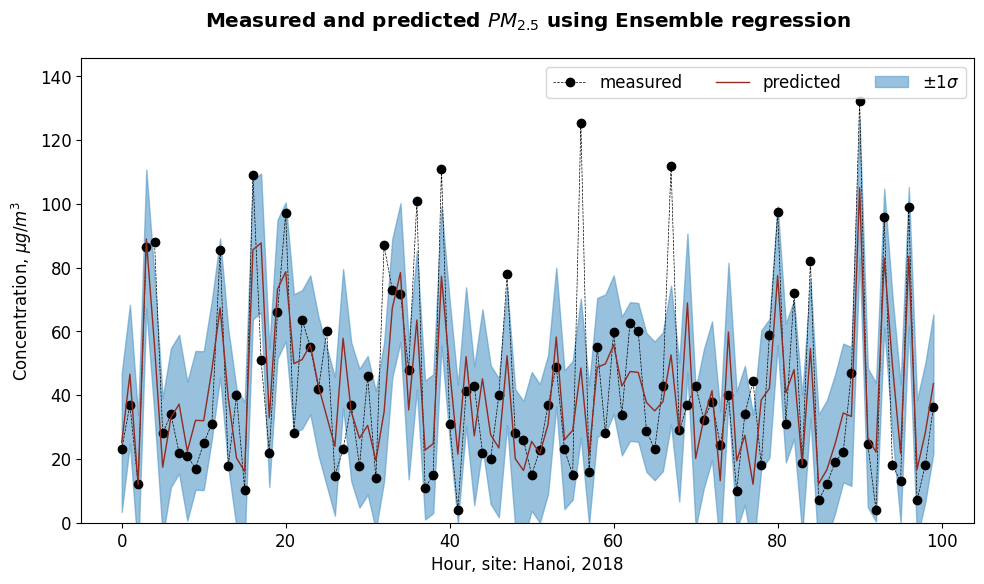

In [261]:
# Call the corrected plotting function which does not include the unsupported 'optimize' argument
plot_results_fixed(label=y_test,
                   prediction=y_entest_p,
                   std_=test_std,
                   savefig=True)

# RMSE
- again, this is Root Mean Squared Error. If we assumed the errors is random, then the distribution of error to the mean value shouls be in standard distribution (Gaussian Distribution). Then the RMSE is the Standard Deviation (SD). The ratio of SD to the mean value in percent is called Relative Standard Deviation.

In [262]:
df = pd.DataFrame(data=results)

In [263]:
df

,linear reg,decisiontree reg,randomforest reg,voting reg,voting reg (Darksky)
train_rmse,25.5,0.0,7.2,10.5,10.5
test_rmse,25.9,28.8,20.1,21.8,21.8


In [264]:
df2 = df.transpose()

In [265]:
df2

,train_rmse,test_rmse
linear reg,25.5,25.9
decisiontree reg,0.0,28.8
randomforest reg,7.2,20.1
voting reg,10.5,21.8
voting reg (Darksky),10.5,21.8


In [267]:
# Use the updated style name compatible with Matplotlib 3.8+
plt.style.use('seaborn-v0_8-whitegrid')

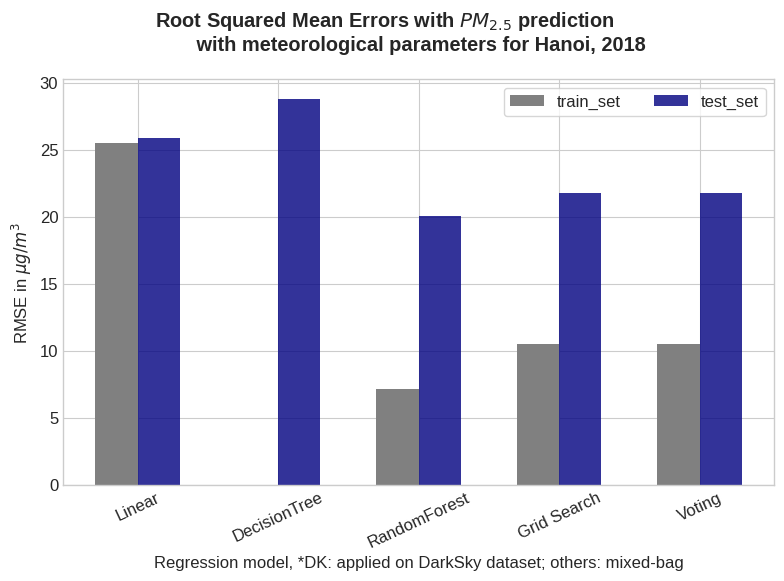

In [268]:
bw = 0.3
idx = np.arange(len(df2))
fig, ax = plt.subplots(figsize=(8,6))
ax.bar(idx-bw/2, df2['train_rmse'], bw, color='gray', label='train_set')
ax.bar(idx+bw/2, df2['test_rmse'], bw, color='navy', alpha=0.8, label='test_set')
ax.set_xticklabels(['','Linear', 'DecisionTree', 'RandomForest',
                    'Grid Search', 'Voting', 'Voting (DK*)'],
                  rotation=25)
ax.set_xlabel('Regression model, *DK: applied on DarkSky dataset; others: mixed-bag')
ax.set_title('Root Squared Mean Errors with $PM_{2.5}$ prediction\
             \n with meteorological parameters for Hanoi, 2018',
            y=1.05,
            weight='bold')
# labels = ax.get_xticklabels()
ax.set_ylabel('RMSE in $\mu g/m^3$')
ax.legend(frameon=True, ncol=2)
fig.tight_layout()
fig.savefig('img/2020Aug_rmse_raw.png')

In [271]:
y.mean()

np.float64(40.758735830458356)

In [273]:
df3 = df2*100/y.mean()

In [274]:
df3

,train_rmse,test_rmse
linear reg,62.563275,63.544660
decisiontree reg,0.000000,70.659699
randomforest reg,17.664925,49.314582
voting reg,25.761349,53.485467
voting reg (Darksky),25.761349,53.485467


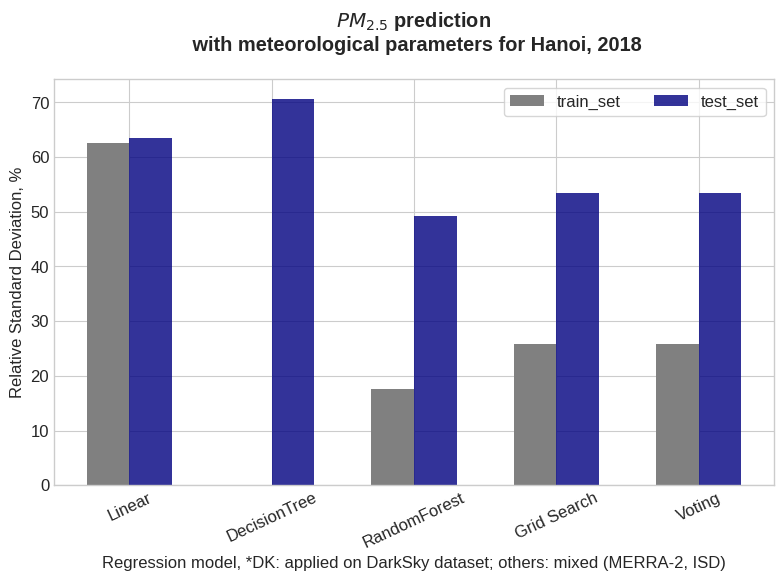

In [275]:
bw = 0.3
idx = np.arange(len(df3))
fig, ax = plt.subplots(figsize=(8,6))
ax.bar(idx-bw/2, df3['train_rmse'], bw, color='gray', label='train_set')
ax.bar(idx+bw/2, df3['test_rmse'], bw, color='navy', alpha=0.8, label='test_set')
ax.set_xticklabels(['','Linear', 'DecisionTree', 'RandomForest',
                    'Grid Search', 'Voting', 'Voting (DK*)'],
                  rotation=25)
ax.set_xlabel('Regression model, *DK: applied on DarkSky dataset; others: mixed (MERRA-2, ISD)')
ax.set_title('$PM_{2.5}$ prediction\n with meteorological parameters for Hanoi, 2018',
             y=1.05,
            weight='bold')
# labels = ax.get_xticklabels()
ax.set_ylabel('Relative Standard Deviation, %')
ax.legend(frameon=True, ncol=2)
fig.tight_layout()
# fig.tight_layout(rect=(0.1,0.1,0.95, 0.95))
fig.savefig('img/2020Aug_rmse_rsd.png')